In [1]:
# Imports
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from dyMES.model import model
from dyMES.model_k_inf import model as model_k_inf
import dyMES.rfunctions as rf
from sir.sir_scaled import model as sir_model

This notebook isolates the decreasing-*tau* tests for *K* = 400 and *K* = inf in the medium *c0*/medium *d0* case.

In [2]:
def pandemic_func(n, I, params):
    m_effective = (params['m_(t-tau)'] - params['c1'] * params['tau'] * params['d_0'] * n)
    
    return (params['c0'] * params['h'] * n * np.exp(- 1 * (I - 100) / params['K'])) * (m_effective - n) - (params['d_0'] * n)

In [3]:
def new_run_model_for_K(K, new_c0 = 0.006, tau = 0.0001, num_days = 7):
    # Instantiate params
    model_params = {
        'm_0': 100,
        'G': 100,
        'K': K,
        'd_0': 0.2,
        'c0': 0.006,
        'c1': 1,
        'c2': 1,
        'tau': tau,
        '<n>_(t-tau)': 0,
        'm_(t-tau)': 100, # should be set to the same value as m_0
        'h': 1,
    }
    initial_infected = 100

    pandemic_dymes = model(initial_infected, model_params, pandemic_func, 'G')

    pandemic_dymes.update_param('c0', pandemic_dymes.find_steady_state_params('c0'))
    print("Steady state c0:", pandemic_dymes.params['c0'])

    pandemic_dymes.update_param('c0', new_c0 / 100)
    print("Updated c0:", pandemic_dymes.params['c0'])
    pandemic_dymes.only_brute_force_update(num_days, dt = tau)

    return pandemic_dymes

In [4]:
def pandemic_func_K_inf(n, I, params):
    m_effective = (params['m_(t-tau)'] - params['c1'] * params['tau'] * params['d_0'] * n)

    return (params['c0'] * params['h'] * n * np.exp(0)) * (m_effective - n) - (params['d_0'] * n)

In [5]:
def new_run_model_for_K_inf(new_c0 = 0.006, tau = 0.0001, num_days = 7):
  # Instantiate params
  model_params = {
    'm_0': 100,
    'G': 100,
    # 'K': K,
    'd_0': 0.2,
    'c0': 0.006,
    'c1': 1,
    'c2': 1,
    'tau': tau,
    '<n>_(t-tau)': 0,
    'm_(t-tau)': 100, # should be set to the same value as m_0
    'h': 1,
  }
  initial_infected = 100

  pandemic_dymes = model_k_inf(initial_infected, model_params, pandemic_func_K_inf, 'G')

  pandemic_dymes.update_param('c0', pandemic_dymes.find_steady_state_params('c0'))
  print("Steady state c0:", pandemic_dymes.params['c0'])

  pandemic_dymes.update_param('c0', new_c0 / 100)
  print("Updated c0:", pandemic_dymes.params['c0'])
  pandemic_dymes.only_brute_force_update(num_days, dt = tau)

  return pandemic_dymes

# K = 400

In [6]:
K_400 = new_run_model_for_K(400, new_c0 = 0.67, num_days = 65, tau = 0.00001)

Steady state c0: 0.0020618557976405647
Updated c0: 0.0067
0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9
5.0
5.1
5.2
5.3
5.4
5.5
5.6
5.7
5.8
5.9
6.0
6.1
6.2
6.3
6.4
6.5
6.6
6.7
6.8
6.9
7.0
7.1
7.2
7.3
7.4
7.5
7.6
7.7
7.8
7.9
8.0
8.1
8.2
8.3
8.4
8.5
8.6
8.7
8.8
8.9
9.0
9.1
9.2
9.3
9.4
9.5
9.6
9.7
9.8
9.9
10.0
10.1
10.2
10.3
10.4
10.5
10.6
10.7
10.8
10.9
11.0
11.1
11.2
11.3
11.4
11.5
11.6
11.7
11.8
11.9
12.0
12.1
12.2
12.3
12.4
12.5
12.6
12.7
12.8
12.9
13.0
13.1
13.2
13.3
13.4
13.5
13.6
13.7
13.8
13.9
14.0
14.1
14.2
14.3
14.4
14.5
14.6
14.7
14.8
14.9
15.0
15.1
15.2
15.3
15.4
15.5
15.6
15.7
15.8
15.9
16.0
16.1
16.2
16.3
16.4
16.5
16.6
16.7
16.8
16.9
17.0
17.1
17.2
17.3
17.4
17.5
17.6
17.7
17.8
17.9
18.0
18.1
18.2
18.3
18.4
18.5
18.6
18.7
18.8
18.9
19.0
19.1
19.2
19.3
19.4
19.5
19.6
19.7
19.8
19.9
20.0
20.1
20.2
20.3
20.4
20.5
20.6
20.7
20

/Users/meilinyen/Desktop/dymes_public/dyMES/model.py:357: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  new_lambdas = fsolve(constraints, starting_point)
/Users/meilinyen/Desktop/dymes_public/dyMES/rfunctions.py:33: RuntimeWarning: invalid value encountered in scalar divide
  return np.sum(np.array([numerator[i] / denominator[i] for i in range(len(numerator))]))
/Users/meilinyen/Desktop/dymes_public/dyMES/rfunctions.py:37: RuntimeWarning: overflow encountered in exp
  return np.exp(-1 * lambdas[0] * n_array - lambdas[1] * transition_function(n_array, N, params))
/Users/meilinyen/Desktop/dymes_public/dyMES/model.py:337: RuntimeWarning: invalid value encountered in scalar divide
  n_mean = rf.Rn_mean(self.func, self.states[-1], m_effective, self.params, lambdas)/Z
/Users/meilinyen/Desktop/dymes_public/dyMES/model.py:338: RuntimeWarning: invalid value encountered in scalar divide
  f_mean = rf.R_mean(self.func, 

61.6
61.7
61.8
61.9
62.0
62.1
62.2
62.3
62.4
62.5
62.6
62.7
62.8
62.9
63.0
63.1
63.2
63.3
63.4
63.5
63.6
63.7
63.8
63.9
64.0
64.1
64.2
64.3
64.4
64.5
64.6
64.7
64.8
64.9


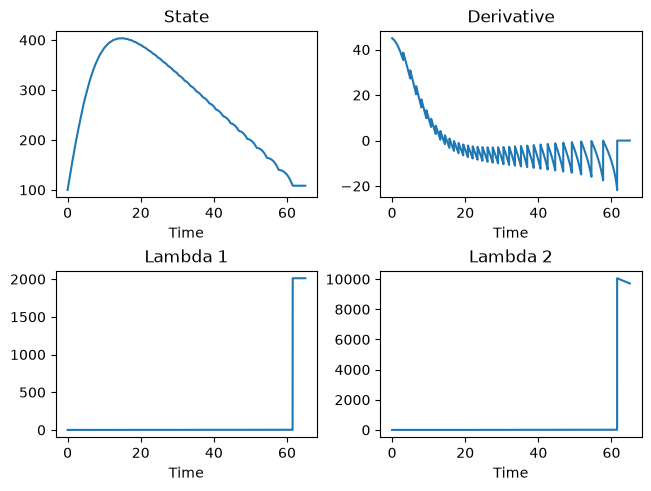

In [7]:
K_400.graph()

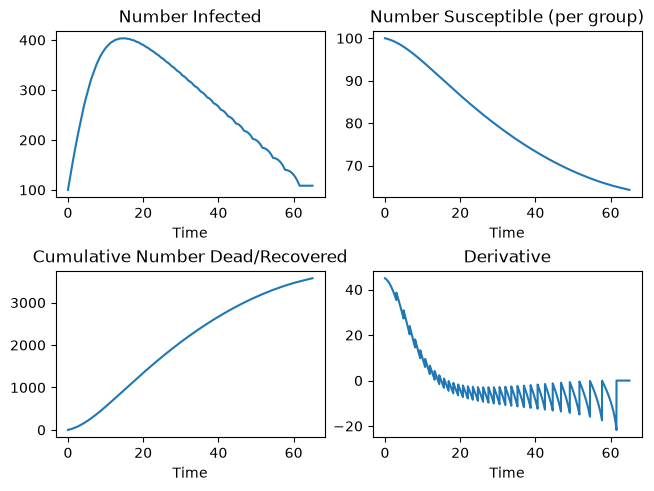

In [8]:
K_400.graph_v2()

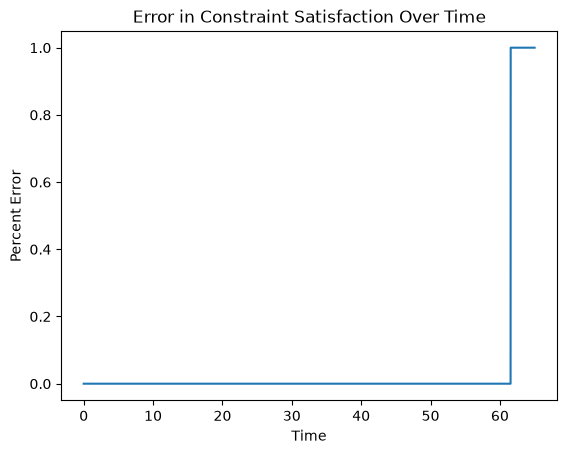

In [9]:
K_400.graph_constraint_errors()

In [20]:
print("Peak state DyMES K = 400:", max(K_400.states),)
print("Time to peak DyMES K = 400:",  np.argmax(K_400.states)/100000)

Peak state DyMES K = 400: 403.5888581011707
Time to peak DyMES K = 400: 14.963


In [13]:
print("DyMES K = 400 time after failure:", K_400.time[-1])
print("DyMES K = 400 state after failure:", K_400.states[-1])
print("DyMES K = 400 m_eff after failure:", K_400.m_effs[-1])
print("DyMES K = 400 number dead after failure:", K_400.num_dead[-1])
print("DyMES K = 400 derivative after failure:", K_400.derivatives[-1])
print("DyMES K = 400 lambda after failure:", K_400.lambdas[-1])
print("DyMES K = 400 error after failure:", K_400.constraint_errors[-1])

DyMES K = 400 time after failure: 64.99999000943237
DyMES K = 400 state after failure: 108.41543399464005
DyMES K = 400 m_eff after failure: 64.25118311282806
DyMES K = 400 number dead after failure: 3574.8816885803762
DyMES K = 400 derivative after failure: 0.0
DyMES K = 400 lambda after failure: [2011.75153962 9712.73477435]
DyMES K = 400 error after failure: 1.0


# K = inf

In [14]:
K_inf = new_run_model_for_K_inf(tau = 0.00001, new_c0 = 0.67, num_days = 50)

Steady state c0: 0.0020618557976405647
Updated c0: 0.0067
0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9
5.0
5.1
5.2
5.3
5.4
5.5
5.6
5.7
5.8
5.9
6.0
6.1
6.2
6.3
6.4
6.5
6.6
6.7
6.8
6.9
7.0
7.1
7.2
7.3
7.4
7.5
7.6
7.7
7.8
7.9
8.0
8.1
8.2
8.3
8.4
8.5
8.6
8.7
8.8
8.9
9.0
9.1
9.2
9.3
9.4
9.5
9.6
9.7
9.8
9.9
10.0
10.1
10.2
10.3
10.4
10.5
10.6
10.7
10.8
10.9
11.0
11.1
11.2
11.3
11.4
11.5
11.6
11.7
11.8
11.9
12.0
12.1
12.2
12.3
12.4
12.5
12.6
12.7
12.8
12.9
13.0
13.1
13.2
13.3
13.4
13.5
13.6
13.7
13.8
13.9
14.0
14.1
14.2
14.3
14.4
14.5
14.6
14.7
14.8
14.9
15.0
15.1
15.2
15.3
15.4
15.5
15.6
15.7
15.8
15.9
16.0
16.1
16.2
16.3
16.4
16.5
16.6
16.7
16.8
16.9
17.0
17.1
17.2
17.3
17.4
17.5
17.6
17.7
17.8
17.9
18.0
18.1
18.2
18.3
18.4
18.5
18.6
18.7
18.8
18.9
19.0
19.1
19.2
19.3
19.4
19.5
19.6
19.7
19.8
19.9
20.0
20.1
20.2
20.3
20.4
20.5
20.6
20.7
20

/Users/meilinyen/Desktop/dymes_public/dyMES/model_k_inf.py:340: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  new_lambdas = fsolve(constraints, starting_point)
/Users/meilinyen/Desktop/dymes_public/dyMES/rfunctions.py:33: RuntimeWarning: invalid value encountered in scalar divide
  return np.sum(np.array([numerator[i] / denominator[i] for i in range(len(numerator))]))


47.0
47.1
47.2
47.3
47.4
47.5
47.6
47.7
47.8
47.9
48.0
48.1
48.2
48.3
48.4
48.5
48.6
48.7
48.8
48.9
49.0
49.1
49.2
49.3
49.4
49.5
49.6
49.7
49.8
49.9


In [16]:
K_inf.only_brute_force_update(30, 0.00001)

0.0


/Users/meilinyen/Desktop/dymes_public/dyMES/model_k_inf.py:340: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  new_lambdas = fsolve(constraints, starting_point)
/Users/meilinyen/Desktop/dymes_public/dyMES/rfunctions.py:33: RuntimeWarning: invalid value encountered in scalar divide
  return np.sum(np.array([numerator[i] / denominator[i] for i in range(len(numerator))]))


0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9
5.0
5.1
5.2
5.3
5.4
5.5
5.6
5.7
5.8
5.9
6.0
6.1
6.2
6.3
6.4
6.5
6.6
6.7
6.8
6.9
7.0
7.1
7.2
7.3
7.4
7.5
7.6
7.7
7.8
7.9
8.0
8.1
8.2
8.3
8.4
8.5
8.6
8.7
8.8
8.9
9.0
9.1
9.2
9.3
9.4
9.5
9.6
9.7
9.8
9.9
10.0
10.1
10.2
10.3
10.4
10.5
10.6
10.7
10.8
10.9
11.0
11.1
11.2
11.3
11.4
11.5
11.6
11.7
11.8
11.9
12.0
12.1
12.2
12.3
12.4
12.5
12.6
12.7
12.8
12.9
13.0
13.1
13.2
13.3
13.4
13.5
13.6
13.7
13.8
13.9
14.0
14.1
14.2
14.3
14.4
14.5
14.6
14.7
14.8
14.9
15.0
15.1
15.2
15.3
15.4
15.5
15.6
15.7
15.8
15.9
16.0
16.1
16.2
16.3
16.4
16.5
16.6
16.7
16.8
16.9
17.0
17.1
17.2
17.3
17.4
17.5
17.6
17.7
17.8
17.9
18.0
18.1
18.2
18.3
18.4
18.5
18.6
18.7
18.8
18.9
19.0
19.1
19.2
19.3
19.4
19.5
19.6
19.7
19.8
19.9
20.0
20.1
20.2
20.3
20.4
20.5
20.6
20.7
20.8
20.9
21.0
21.1
21.2
21.3
21.4
21.5
21.6
21.7
21.8
21.9
22.0

In [17]:
K_inf.states[-1]

np.float64(143.06532381530334)

In [21]:
print("Peak state DyMES K = inf:", max(K_inf.states),)
print("Time to peak DyMES K = inf:",  np.argmax(K_inf.states)/100000)

Peak state DyMES K = inf: 613.589989777978
Time to peak DyMES K = inf: 19.05117


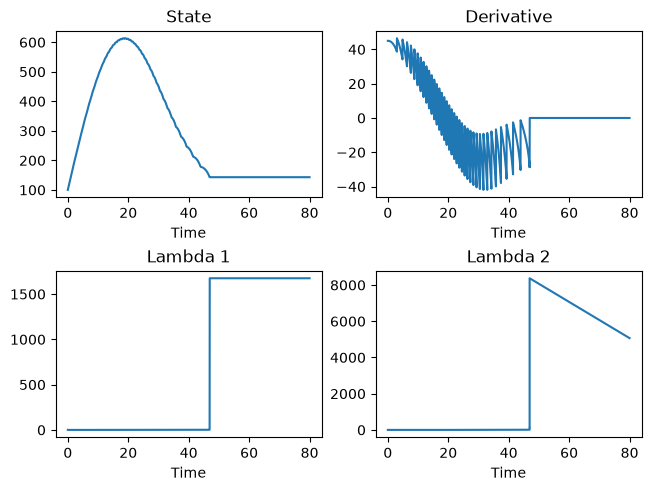

In [22]:
K_inf.graph()

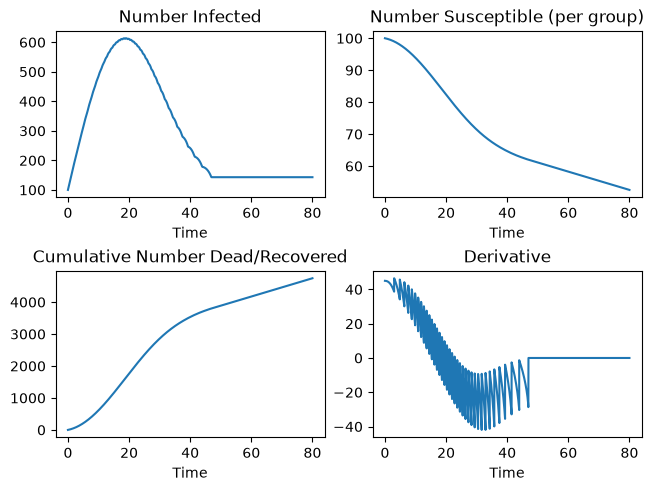

In [23]:
K_inf.graph_v2()

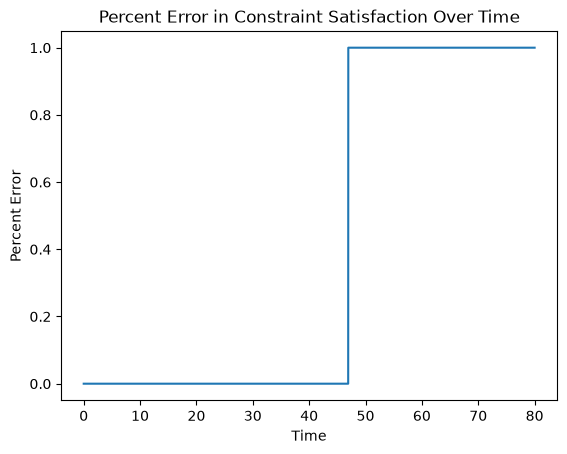

In [24]:
K_inf.graph_constraint_errors()

In [25]:
print("Peak state DyMES K = inf:", max(K_inf.states),)
print("Time to peak DyMES K = inf:",  np.argmax(K_inf.states)/100000)

Peak state DyMES K = inf: 613.589989777978
Time to peak DyMES K = inf: 19.05117


In [26]:
print("DyMES K = inf time after failure:", K_inf.time[-1])
print("DyMES K = inf state after failure:", K_inf.states[-1])
print("DyMES K = inf m_eff after failure:", K_inf.m_effs[-1])
print("DyMES K = inf number dead after failure:", K_inf.num_dead[-1])
print("DyMES K = inf derivative after failure:", K_inf.derivatives[-1])
print("DyMES K = inf lambda after failure:", K_inf.lambdas[-1])
print("DyMES K = inf error after failure:", K_inf.constraint_errors[-1])

DyMES K = inf time after failure: 79.99999001419357
DyMES K = inf state after failure: 143.06532381530334
DyMES K = inf m_eff after failure: 52.53682531294469
DyMES K = inf number dead after failure: 4746.317468048775
DyMES K = inf derivative after failure: 0.0
DyMES K = inf lambda after failure: [1674.99563869 5067.24834796]
DyMES K = inf error after failure: 1.0
